In [2]:
# Reading the csv data file using pandas
import pandas as pd
import numpy as np 
train_data = pd.read_csv("week2.csv",skiprows=1,header=None)
train_data.columns = ["X1","X2","y"] # Give titles to the columns
print(train_data.head())
# print(df.shape)
X1=train_data.iloc [: ,0]
X2=train_data.iloc [: ,1]
y=train_data.iloc [: ,2]

     X1    X2  y
0 -0.49  0.39 -1
1  0.24  0.99 -1
2 -0.21 -0.85  1
3  0.54  0.78 -1
4  0.50 -0.83  1


In [3]:
%pip install seaborn

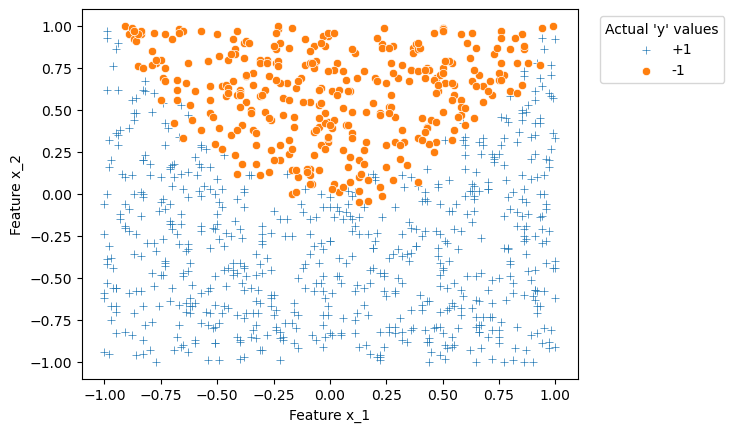

In [4]:
#Part a) i) Data visualized through a scatterplot using seaborn and matplotlib libraries
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=train_data,
    x=X1[y==1],
    y=X2[y==1],
    marker="+",
    label="+1"
)

sns.scatterplot(
    data=train_data,
    x=X1[y==-1],
    y=X2[y==-1],
    marker="o",
    label="-1"
)

plt.xlabel('Feature x_1')
plt.ylabel('Feature x_2')
plt.legend(
    loc='upper left',
    bbox_to_anchor = (1.03,1),
    title = "Actual 'y' values"
)
plt.show()

In [5]:
# Check for any missing/null values in the data
train_data.isnull().sum()

X1    0
X2    0
y     0
dtype: int64

# Logistic Regression Classifier model

In [6]:
# Defining the feature and target variables
X_train = train_data.drop(['y'],axis=1) # feature variables dataframe
y_train = train_data['y'] # target variable dataframe

In [6]:
X_train.head() # Added the print statment for verification

,X1,X2
0,-0.49,0.39
1,0.24,0.99
2,-0.21,-0.85
3,0.54,0.78
4,0.50,-0.83


In [23]:
# Train the logistic regression classfier model using the training data
from sklearn.linear_model import LogisticRegression

log_reg_model = LogisticRegression(max_iter=500)
log_reg_model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [8]:
# Used the above trained model for predicting the target values 
y_pred = log_reg_model.predict(X_train)
#print("Predicted values: ",y_pred)

In [9]:
# Output the predicted values into a new csv file
output = pd.DataFrame({
    'Feature x1': X_train['X1'],
    'Feature x2': X_train['X2'],
    'Actual target value': y_train,
    'Predicted target value': y_pred
})

output.to_csv("LogisticRegression.csv",index=False)
print("Output file for Logistic Regression model generated successfully")

Output file generated successfully


# Added the predicted values to the 2D plot generated in part(i)

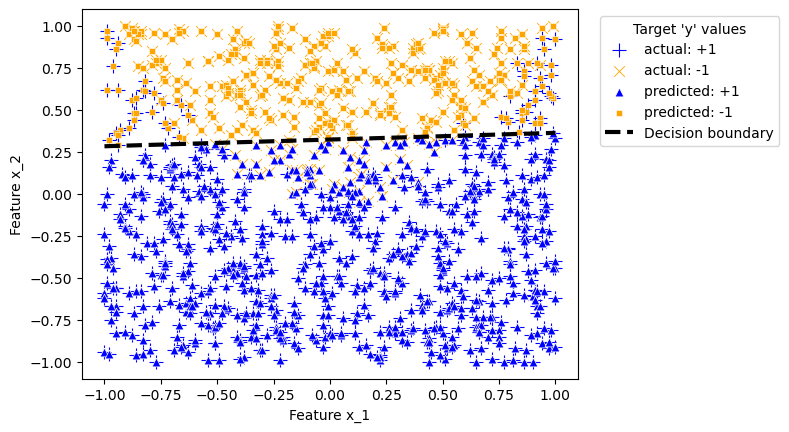

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    x=X1[y_train==1],
    y=X2[y_train==1],
    marker="+",
    color="blue",
    s=100,
    label="actual: +1"
)

sns.scatterplot(
    x=X1[y_train==-1],
    y=X2[y_train==-1],
    marker="x",
    color="orange",
    s=60,
    label="actual: -1"
)

# Predicted values
sns.scatterplot(
    x=X1[y_pred==1],
    y=X2[y_pred==1],
    marker="^",
    color="blue",
    s=40,
    label="predicted: +1"
)

sns.scatterplot(
    x=X1[y_pred==-1],
    y=X2[y_pred==-1],
    marker="s",
    color="orange",
    s=25,
    label="predicted: -1"
)

# Decision boundary line
# Step (1): Defining and accessing parameter values of the trained model
θo = log_reg_model.intercept_
θ1 = log_reg_model.coef_[0][0]
θ2 = log_reg_model.coef_[0][1]

# Step (2): x1 values for the decision boundary line
x1_line = np.linspace(X1.min(),X1.max(),200)

# Step (3): Decision boundary line to be plotted where y=0
x2_line = -(θo + θ1*x1_line)/θ2

# Step (4): Plotting the line
plt.plot(
    x1_line,
    x2_line,
    linestyle = '--',
    color = 'black',
    linewidth = 3,
    label = 'Decision boundary'
)

plt.xlabel('Feature x_1')
plt.ylabel('Feature x_2')
plt.legend(
    loc='upper left',
    bbox_to_anchor = (1.03,1),
    title = "Target 'y' values"
)

plt.show()

In [30]:
# Parameter values of the above trained model
print("Intercept: ", θo)
print("Coefficients: ",θ1, θ2)

Intercept:  [1.61671945]
Coefficients:  0.19942624663792383 -4.9950511280005605


# Accuracy score of the Logistic Regression model

In [12]:
# Accuracy score between the predictions and the training data
from sklearn.metrics import accuracy_score
score = accuracy_score(y,y_pred)
print(score)

0.8748748748748749


# Part(2) Linear SVC

C: 0.001
Intercept:  [0.20731353]
Coefficients:  [[ 0.01384404 -0.48495805]]
Accuracy score:  0.8598598598598599


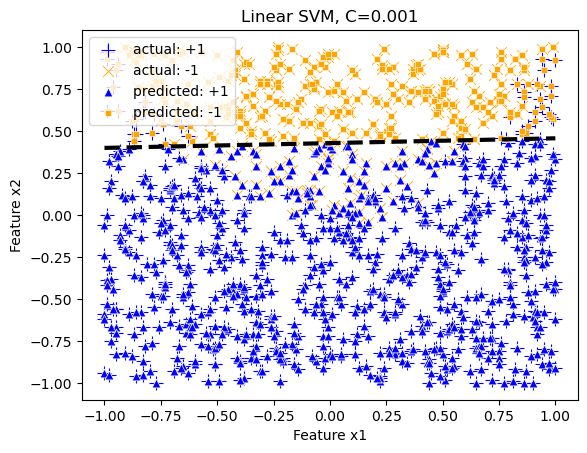

C: 1.0
Intercept:  [0.57975202]
Coefficients:  [[ 0.06673397 -1.8251598 ]]
Accuracy score:  0.8738738738738738


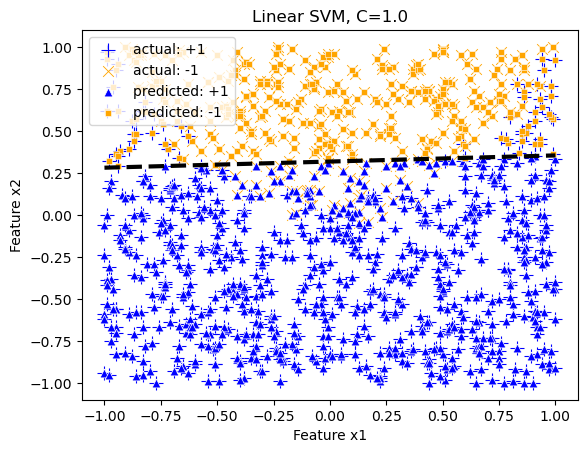

C: 100
Intercept:  [0.58630431]
Coefficients:  [[ 0.067831   -1.84317104]]
Accuracy score:  0.8748748748748749


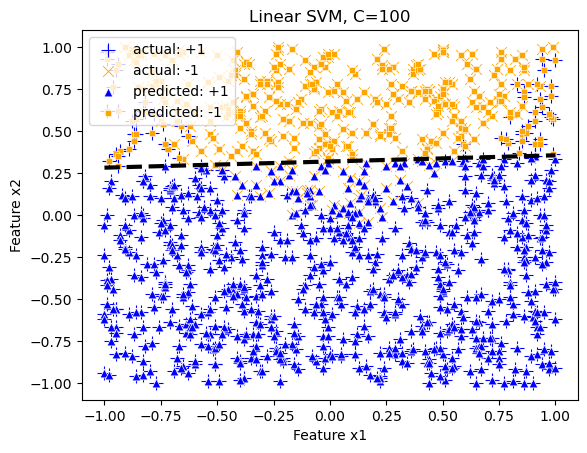

In [33]:
# Train a linear SVM classifier model using the same training data
from sklearn.svm import LinearSVC
C_val = [0.001,1.0,100] # Different values of penalty parameter C

for C in C_val: 
    svm_model = LinearSVC(C=C)
    svm_model.fit(X_train,y_train)

    # Predicting target values
    y_pred_svm = svm_model.predict(X_train)
    print("C:",C)
    print("Intercept: ",svm_model.intercept_)
    print("Coefficients: ",svm_model.coef_)
    #print("Predictions: ",y_pred_svm)

    plt.figure() # To plot 3 different plots

    sns.scatterplot(
    x=X1[y_train==1],
    y=X2[y_train==1],
    marker="+",
    color="blue",
    s=100,
    label="actual: +1"
    )

    sns.scatterplot(
    x=X1[y_train==-1],
    y=X2[y_train==-1],
    marker="x",
    color="orange",
    s=60,
    label="actual: -1"
    )

    # Predicted values using LinearSVC
    sns.scatterplot(
    x=X1[y_pred_svm==1],
    y=X2[y_pred_svm==1],
    marker="^",
    color="blue",
    s=40,
    label="predicted: +1"
    )

    sns.scatterplot(
    x=X1[y_pred_svm==-1],
    y=X2[y_pred_svm==-1],
    marker="s",
    color="orange",
    s=25,
    label="predicted: -1"
    )

    score_svm = accuracy_score(y,y_pred_svm)
    print("Accuracy score: ", score_svm)

    # Decision boundary line
    # Step (1): Defining and accessing parameter values of the trained model
    θo = svm_model.intercept_[0]
    θ1 = svm_model.coef_[0][0]
    θ2 = svm_model.coef_[0][1]

    # Step (2): x1 values for the decision boundary line
    x1_line = np.linspace(X1.min(),X1.max(),50)

    # Step (3): Decision boundary line to be plotted where y=0
    x2_line = -(θo + θ1*x1_line)/θ2

    # Step (4): Plotting the line
    plt.plot(
    x1_line,
    x2_line,
    linestyle = '--',
    color = 'black',
    linewidth = 3,
    label = 'Decision boundary'
    )

    plt.xlabel("Feature x1")
    plt.ylabel("Feature x2")
    plt.title(f"Linear SVM, C={C}")
    #plt.tight_layout()
    plt.show()
    

# Train a quadratic logistic regression classifier model on top of the initial part(a) logistic regression classifier model

In [34]:
# Extended Logistic Regression model (added 2 additional squared input features)
X_train_poly=np.column_stack((X_train,X_train**2))
#print(X_train_poly)
extended_log_reg_model = LogisticRegression(max_iter=100).fit(X_train_poly,y_train)
y_pred_extended = extended_log_reg_model.predict(X_train_poly)

In [35]:
# print(y_predicted_extended)
print(extended_log_reg_model.intercept_)
print(extended_log_reg_model.coef_)

[0.23573279]
[[-0.06733566 -6.74194572  6.57881152 -0.84097541]]


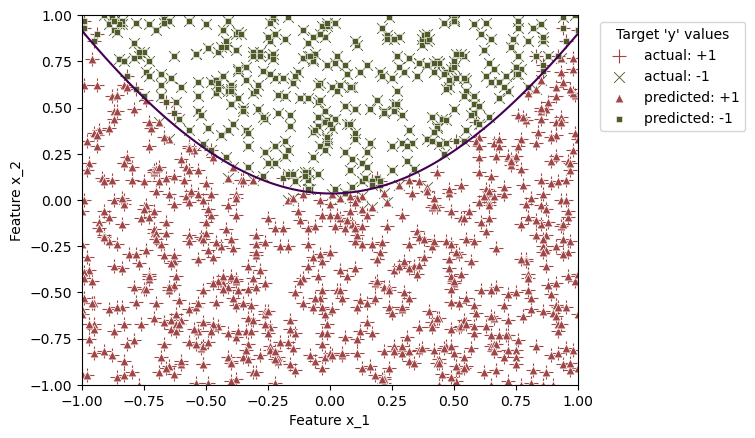

In [36]:
# Plotting the predicted and actual target values
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    x=X1[y_train==1],
    y=X2[y_train==1],
    marker="+",
    color="#A14646",
    s=100,
    label="actual: +1"
)

sns.scatterplot(
    x=X1[y_train==-1],
    y=X2[y_train==-1],
    marker="x",
    color="#4F5B2A",
    s=60,
    label="actual: -1"
)

# Predicted values
sns.scatterplot(
    x=X1[y_pred_extended==1],
    y=X2[y_pred_extended==1],
    marker="^",
    color="#A14646",
    s=40,
    label="predicted: +1"
)

sns.scatterplot(
    x=X1[y_pred_extended==-1],
    y=X2[y_pred_extended==-1],
    marker="s",
    color="#4F5B2A",
    s=25,
    label="predicted: -1"
)

# Decision boundary curve
# Step (1): Defining and accessing parameter values of the trained model
θo = extended_log_reg_model.intercept_
θ1 = extended_log_reg_model.coef_[0][0]
θ2 = extended_log_reg_model.coef_[0][1]
θ3 = extended_log_reg_model.coef_[0][2]
θ4 = extended_log_reg_model.coef_[0][3]

# Decision boundary curve
# Step (2): Forming a grid (two 2D arrays) of all the X1 and X2 data points
x1_line_grid = np.linspace(X_train.iloc[:, 0].min(),X_train.iloc[:, 0].max(),200)
x2_line_grid = np.linspace(X_train.iloc[:, 1].min(),X_train.iloc[:, 1].max(),200)

x1_grid,x2_grid = np.meshgrid(x1_line_grid,x2_line_grid)

# Step (3): Flatten the above created 2D grids into single long 1D array for each of the inputs for calculating the linear score of the model
poly_grid = np.column_stack((
    x1_grid.ravel(), # ravel converts the 2D grid into a single long 1D array
    x2_grid.ravel(),
    x1_grid.ravel()**2,
    x2_grid.ravel()**2
))

# Step (4): Calculate the extended model's linear score
linear_score = extended_log_reg_model.decision_function(poly_grid)

# Step (5): Convert the linear score values back into a 2D grid for plotting the decision boundary curve
linear_score = linear_score.reshape(x1_grid.shape)

# Step (6): Plot the decision boundary curve where the model score is 0
plt.contour(
    x1_grid,
    x2_grid,
    linear_score,
    levels = [0]
)

plt.xlabel('Feature x_1')
plt.ylabel('Feature x_2')
plt.legend(
    loc='upper left',
    bbox_to_anchor = (1.03,1),
    title = "Target 'y' values"
)

plt.show()

# Accuracy score of the extended Logistic Regression classifier model

In [37]:
score_extended = accuracy_score(y,y_pred_extended)
print(score_extended)

0.9579579579579579


In [39]:
# Baseline accuracy score obtained using ZeroR classifier method
from collections import Counter

count = Counter(y)
majority_class = count.most_common()[0][0] #Tells us which target value class appears the most no. of times
baseline_score = np.mean(y==majority_class)

print("Majority class: ",majority_class)
print("Baseline predictor score: ",baseline_score)

Majority class:  1
Baseline predictor score:  0.6556556556556556
